In [ ]:
# 1. استيراد المكتبات الأساسية لمعالجة البيانات والرسومات البيانية
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

print("تم استيراد كافة المكتبات بنجاح!")

تم استيراد كافة المكتبات بنجاح!


In [ ]:
# 2. رفع ملف البيانات من الجهاز
uploaded = files.upload()

# تحديد أسماء الأعمدة الخاصة ببيانات مرض السكري
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

# قراءة الملف الذي تم رفعه تلقائياً
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename, names=columns)

# عرض أول 5 صفوف للتأكد من قراءة البيانات بنجاح
display(df.head())

Saving pima-indians-diabetes.data.csv to pima-indians-diabetes.data.csv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
# 3. معالجة القيم الشاذة والأصفار في الأعمدة الحيوية الحساسة
columns_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in columns_to_fix:
    df[col] = df[col].replace(0, np.nan)
    mean_val = df[col].mean()
    df[col].fillna(mean_val, inplace=True)

print("تم تنظيف البيانات ومعالجة الأصفار بنجاح تام!")
print("أبعاد الجدول بعد التنظيف (صفوف، أعمدة):", df.shape)

# التأكد من خلو الجدول من أي قيم مفقودة
print("\nعدد القيم المفقودة في كل عمود:")
print(df.isnull().sum())

تم تنظيف البيانات ومعالجة الأصفار بنجاح تام!
أبعاد الجدول بعد التنظيف (صفوف، أعمدة): (768, 9)

عدد القيم المفقودة في كل عمود:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


/tmp/ipykernel_897/1540053484.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mean_val, inplace=True)


In [ ]:
# 4. عرض الملخص الإحصائي الشامل للبيانات النظيفة
display(df.describe())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.790942,85.021108,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,155.548223,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,155.548223,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


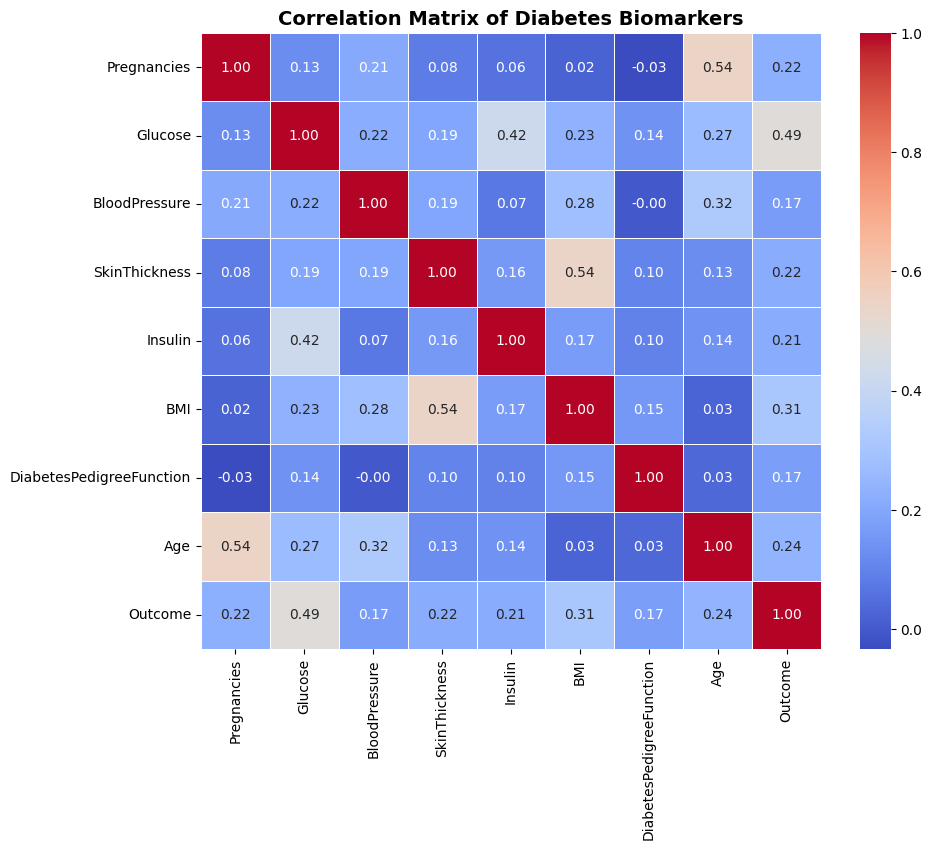

In [ ]:
# 5. رسم مصفوفة الارتباط باللغة الإنجليزية لمنع تفكك النصوص
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Diabetes Biomarkers', fontsize=14, fontweight='bold')
plt.show()

/tmp/ipykernel_897/3622953002.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette='Set2')


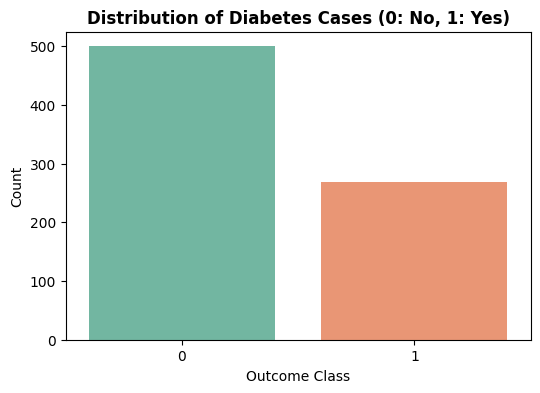

In [ ]:
# 6. رسم بياني يوضح توزيع الحالات (0 = غير مصاب، 1 = مصاب)
plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df, palette='Set2')
plt.title('Distribution of Diabetes Cases (0: No, 1: Yes)', fontsize=12, fontweight='bold')
plt.xlabel('Outcome Class')
plt.ylabel('Count')
plt.show()